# **U-Net 모델 구현**

✅ 아래 코드는 PyTorch로 작성한 간단한 U-Net 모델입니다.

✅ 주요 목표: 작은 이미지 세트로 segmentation 학습을 테스트하기!

✅ 특징: 업샘플링(deconv/upsample 선택 가능), 입력 스케일링, Gaussian noise 추가, 배치 정규화 적용

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# --- 작은 U-Net 정의 ---
class UNetSmall(nn.Module):
    def __init__(self, upsample_mode='deconv', net_scaling=None, edge_crop=0, gaussian_noise_std=0.1):
        super().__init__()
        self.net_scaling = net_scaling
        self.edge_crop = edge_crop
        self.gaussian_noise_std = gaussian_noise_std
        self.upsample_mode = upsample_mode

         # Convolution Block: Conv -> ReLU -> Conv -> ReLU
        def conv_block(in_c, out_c):
            return nn.Sequential(
                nn.Conv2d(in_c, out_c, 3, padding=1),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_c, out_c, 3, padding=1),
                nn.ReLU(inplace=True)
            )

        # 인코더 부분 목표 -> 128 까지!
        self.enc1 = conv_block(3, 16)
        self.enc2 = conv_block(16, 32)
        self.enc3 = conv_block(32, 64)
        self.enc4 = conv_block(64, 128)
        # Bottleneck
        self.center = conv_block(128, 128)
        self.pool = nn.MaxPool2d(2)


        # 업샘플링 부분 정의 (deconv 또는 upsample+conv) 로
        if upsample_mode == 'deconv':
            def upsample_layer(in_c, out_c):
                return nn.ConvTranspose2d(in_c, out_c, 2, stride=2)
        else:
            def upsample_layer(in_c, out_c):
                return nn.Sequential(
                    nn.Upsample(scale_factor=2, mode='nearest'),
                    nn.Conv2d(in_c, out_c, 1)
                )
        # 디코더 부분
        self.up4 = upsample_layer(128, 128)
        self.dec4 = conv_block(256, 128)
        self.up3 = upsample_layer(128, 64)
        self.dec3 = conv_block(128, 64)
        self.up2 = upsample_layer(64, 32)
        self.dec2 = conv_block(64, 32)
        self.up1 = upsample_layer(32, 16)
        self.dec1 = conv_block(32, 16)

        # 최종 출력: 1채널(segmentation mask)
        self.final = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        if self.net_scaling:
        # 입력 스케일링
            x = F.avg_pool2d(x, self.net_scaling)
        # Gaussian noise 추가
        if self.gaussian_noise_std:
            noise = torch.randn_like(x) * self.gaussian_noise_std
            x = x + noise

        # 배치 정규화 적용
        x = F.batch_norm(x, running_mean=None, running_var=None, training=True)

        # 인코더
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        # Bottleneck
        center = self.center(self.pool(e4))

        # 디코더 + Skip Connection
        d4 = self.up4(center)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        out = self.final(d1)
        out = torch.sigmoid(out)
         # Crop + Pad
        if self.edge_crop > 0:
            out = out[:, :, self.edge_crop:-self.edge_crop, self.edge_crop:-self.edge_crop]
            out = F.pad(out, (self.edge_crop, self.edge_crop, self.edge_crop, self.edge_crop))
        # Upsample 다시 확대
        if self.net_scaling:
            out = F.interpolate(out, scale_factor=self.net_scaling, mode='nearest')

        return out

## **학습용 데이터 생성하기**

In [ ]:
batch_size = 32
x = torch.randn(batch_size, 3, 128, 128)  # RGB 이미지
y = (torch.rand(batch_size, 1, 128, 128) > 0.5).float()  # 랜덤 이진 마스크

dataset = TensorDataset(x, y)
loader = DataLoader(dataset, batch_size=2, shuffle=True)

## **데이터 시각화**

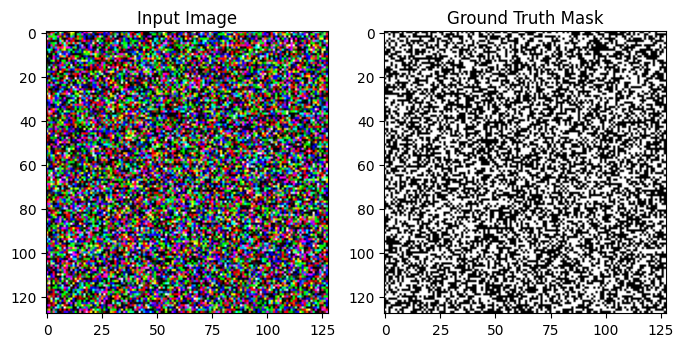

In [ ]:
import matplotlib.pyplot as plt
# 첫 번째 이미지를 시각화
sample_x = x[0]
sample_y = y[0]

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(sample_x.permute(1, 2, 0).numpy())
plt.title('Input Image')

plt.subplot(1, 2, 2)
plt.imshow(sample_y.squeeze().numpy(), cmap='gray')
plt.title('Ground Truth Mask')
plt.show()

## **모델 선언 및 학습**

In [ ]:
# --- 모델 선언 및 학습 ---
model = UNetSmall(upsample_mode='deconv', net_scaling=None, edge_crop=0)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.BCELoss()

# 간단히 30 epoch만
for epoch in range(10):
    model.train()
    total_loss = 0
    for xb, yb in loader:
        pred = model(xb)
        loss = criterion(pred, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(loader):.4f}")

Epoch 1, Loss: 0.6932
Epoch 2, Loss: 0.6931
Epoch 3, Loss: 0.6931
Epoch 4, Loss: 0.6931
Epoch 5, Loss: 0.6931
Epoch 6, Loss: 0.6931
Epoch 7, Loss: 0.6930
Epoch 8, Loss: 0.6930
Epoch 9, Loss: 0.6929
Epoch 10, Loss: 0.6929


## **아래 주석을 풀고 U-Net 모델에 대해 간단히 설명해주세요 😀**

[답변]

U-Net은 의료 영상 등 적은 데이터로도 픽셀 단위 분할(semantic segmentation)을 수행하기 위해 제안된 인코더-디코더 구조의 완전합성곱 신경망입니다.

- **인코더(수축 경로)**: 합성곱과 맥스풀링을 반복하며 공간 해상도를 줄이고 채널 수를 늘려 이미지의 context(의미 정보)를 추출합니다. 위 코드에서는 enc1~enc4와 pool이 이 역할을 합니다.
- **병목(Bottleneck)**: 인코더의 가장 깊은 지점으로, 가장 추상화된 특징을 담고 있습니다. 위 코드의 center에 해당합니다.
- **디코더(확장 경로)**: 전치 합성곱(ConvTranspose2d) 또는 업샘플링+합성곱으로 해상도를 다시 키우면서, 각 단계에서 인코더의 동일 해상도 특징맵을 **skip connection**으로 연결(concat)하여 세밀한 위치 정보를 보완합니다. 위 코드의 up4~up1, dec4~dec1, torch.cat이 이에 해당합니다.
- **최종층**: 1x1 합성곱으로 채널 수를 1(마스크)로 줄이고 시그모이드를 적용해 각 픽셀이 객체에 속할 확률을 출력합니다.

이러한 U자형 구조와 skip connection 덕분에 U-Net은 context 정보와 위치 정보를 동시에 보존할 수 있어, 적은 수의 학습 데이터로도 정확한 분할 경계를 예측할 수 있습니다.

---



## **아래 주석을 풀고 DeepLabv1, v2, v3. v3+  모델에 대해 각각 간단히 설명해주세요 🐶**

[답변]

DeepLab 계열은 Dilated(Atrous) Convolution과 CRF 등을 활용해 분할 성능을 높여온 시맨틱 세그멘테이션 모델 시리즈입니다.

---

[DeepLab v1]
VGG 기반 네트워크의 뒷부분 풀링층을 제거하고 Atrous(팽창) Convolution을 적용하여, 해상도 손실을 줄이면서도 넓은 수용 영역(receptive field)을 확보합니다. 네트워크의 거친 출력 결과는 후처리 단계에서 완전 연결 조건부 무작위장(Fully Connected CRF)으로 경계를 다듬어 최종 분할 맵을 생성합니다.

[DeepLab v2]
v1의 구조에 ASPP(Atrous Spatial Pyramid Pooling)를 도입하여, 서로 다른 팽창 비율(rate)을 가진 여러 Atrous Convolution을 병렬로 적용한 뒤 그 결과를 결합합니다. 이를 통해 다양한 크기의 객체를 동시에 효과적으로 인식할 수 있으며, 백본으로 ResNet을 사용하기 시작했습니다.

[DeepLab v3]
ASPP 모듈을 개선하여 1x1 합성곱과 전역 평균 풀링(global average pooling) 분기를 추가하고, 배치 정규화를 적용해 학습을 안정화했습니다. 또한 후처리용 CRF를 제거하여 신경망만으로 end-to-end 학습이 가능하도록 구조를 단순화했습니다.

[DeepLab v3+]
v3의 ASPP 기반 인코더에 간단한 디코더 모듈을 추가한 인코더-디코더 구조입니다. 인코더에서 추출한 추상화된 특징을 디코더에서 저수준 특징과 결합하며 점진적으로 업샘플링함으로써, 객체의 경계를 더 정교하게 복원합니다. 또한 Depthwise Separable Convolution을 Atrous Convolution에 적용(Atrous Separable Convolution)하여 연산량을 줄이면서도 성능을 유지했습니다.
